# Pruebas retrospectivas de la pérdida esperada: Acerbi-Szekely con valores críticos simulados, Du-Escanciano y McNeil-Frey

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 03 de este tema (las pruebas retrospectivas de excepciones)
- **Tiempo de lectura:** unos 45 minutos

**Pregunta:** Cuando las pérdidas más allá del VaR son mayores que la pérdida esperada pronosticada, ¿qué prueba del año de crisis lo ve: el estadístico de Acerbi-Szekely, las pruebas de Du-Escanciano o los residuos de McNeil-Frey?

## Objetivos

Al terminar este notebook puedes:

- explicar por qué un conteo de excepciones del VaR no puede probar una pérdida esperada, y qué miden en su lugar los estadísticos $Z_1$ y $Z_2$ de Acerbi-Szekely;
- calcular $Z_2$ a mano desde las pérdidas, el VaR y la ES de los 14 modelos de la crisis de 2008 que pronostican una ES;
- decir qué pide el motor al usuario para dar un valor crítico, qué nula suministra Contraste, y por qué los valores críticos difieren de un modelo a otro;
- comparar el valor crítico simulado de cada modelo con el punto de referencia publicado de $-0,70$ y $-1,8$, y decir qué es y qué no es esa referencia;
- correr las pruebas de Du-Escanciano y McNeil-Frey sobre un modelo cuya distribución predictiva se conoce, y leer qué agrega cada una a $Z_2$.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas, imprimir las versiones, hacer importable el código de casos del proceso y
# nombrar las luces
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Las pruebas de ES necesitan la pérdida realizada de cada día, así que el notebook trabaja con las dos ventanas del caso C11 que la versionan: `fx-2008` (el euro frente al dólar, 251 días) y `rates-2022` (una posición en el bono del Tesoro a 10 años, 249 días), ambas construidas sobre series `mirror-allowed`. Para cada uno de los 17 modelos y cada nivel de cola los archivos guardan el VaR y la ES (pérdidas positivas) y, para los modelos que pronostican una ES, el resultado de Acerbi-Szekely versionado con el histograma de su nula simulada. `equity-2007-09` se lee solo por sus filas versionadas: sus retornos son solo derivados.

Tres escalones no pronostican una ES (`cf-rolling`, `caviar-sav`, `caviar-as`), así que las pruebas de ES no se les aplican y el motor devolvería `not_evaluated`; el notebook los omite. La celda siguiente carga los archivos y lista qué modelos tienen una ES.

In [2]:
# Cargar las dos ventanas que versionan las pérdidas realizadas y listar los modelos que pronostican una ES
C11 = ROOT / "data" / "derived" / "C11"
docs = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8")) for w in ("fx-2008", "rates-2022")}
fx = docs["fx-2008"]["outputs"]
models = {m["model_id"]: m for m in fx["models"]}
with_es = [mid for mid, m in models.items() if all(lv["es_status"] == "forecast" for lv in m["by_level"])]
loss = np.array(fx["grid"]["realised_loss"]["loss"])
print("modelos con ES:", len(with_es), "de", len(models))
print("sin ES:", [mid for mid in models if mid not in with_es])
print("fx-2008: pérdidas realizadas", loss.size, "| niveles de cola", [lv["alpha"] for lv in fx["levels"]])

modelos con ES: 14 de 17
sin ES: ['cf-rolling', 'caviar-sav', 'caviar-as']
fx-2008: pérdidas realizadas 251 | niveles de cola [0.01, 0.025]


## Método

### Paso 1: por qué la ES necesita su propia prueba, y los estadísticos $Z_1$ y $Z_2$

La pérdida esperada es una afirmación sobre **cuán grandes** son las pérdidas cuando se supera el VaR. El número de excepciones no dice nada de su tamaño: dos modelos con el mismo VaR y el mismo conteo pueden tener una ES muy distinta, y solo uno de ellos es correcto. Acerbi y Szekely (2014) contrastan la ES con estadísticos construidos desde el tamaño de la pérdida en los días de excepción relativo a la ES pronosticada. Con $X_t = -\text{pérdida}_t$, $I_t = \mathbb 1\{\text{pérdida}_t > \text{VaR}_t\}$ y $N_T = \sum_t I_t$:

$$Z_1 = \frac{1}{N_T}\sum_{t=1}^{T}\frac{X_t\,I_t}{\mathrm{ES}_t} + 1, \qquad Z_2 = \sum_{t=1}^{T}\frac{X_t\,I_t}{T\,\alpha\,\mathrm{ES}_t} + 1$$

$Z_1$ promedia, solo sobre los días de excepción, la razón entre la pérdida realizada y la ES pronosticada: vale 0 cuando las pérdidas son, en promedio, tan grandes como dice la ES, y es negativo cuando son mayores. $Z_2$ reemplaza $N_T$ por el conteo esperado $T\alpha$, de modo que penaliza también un **número equivocado** de excepciones. Ambos tienen esperanza 0 bajo la nula de que los pronósticos son correctos, y ambos son negativos cuando se subestima el riesgo. La celda calcula ambos a mano para cada modelo con ES, en ambos niveles, y dibuja el $Z_2$ de cada modelo.

model        alpha    exc.        Z1        Z2
hs-250       0.010      10   -0.0691   -3.2592
hs-250       0.025      13   -0.1350   -1.3513
dn-rolling   0.010      23   -0.2444  -10.4033
dn-rolling   0.025      35   -0.2394   -5.9131
ewma         0.010       3   -0.1242   -0.3437
ewma         0.025       8   -0.0323   -0.3160
garch-t      0.010       3   -0.0402   -0.2433
garch-t      0.025       7   -0.0117   -0.1286


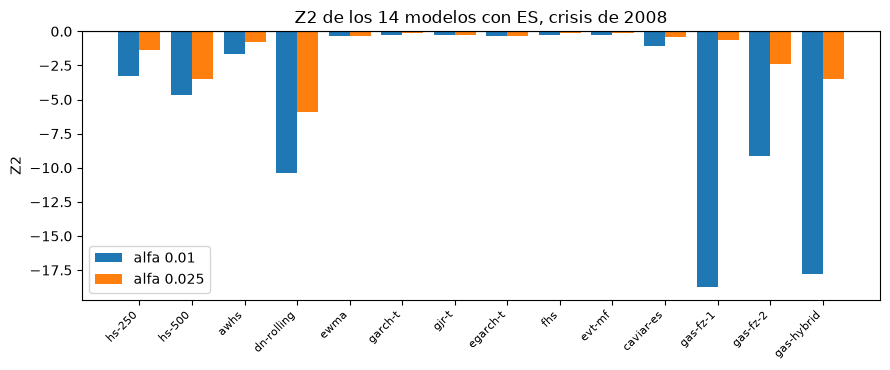

In [3]:
# Z1 y Z2 a mano desde las pérdidas, el VaR y la ES de cada modelo con ES, y el Z2 de cada modelo dibujado
by_hand = {}
for mid in with_es:
    for level in models[mid]["by_level"]:
        alpha = level["alpha"]
        var, es = np.array(level["var"]), np.array(level["es"])
        exceed = loss > var
        ratio = loss[exceed] / es[exceed]
        z1 = 1.0 - ratio.mean() if exceed.any() else float("nan")
        by_hand[(mid, alpha)] = (int(exceed.sum()), z1, 1.0 - ratio.sum() / (loss.size * alpha))
print(f"{'model':11s} {'alpha':>6s} {'exc.':>7s} {'Z1':>9s} {'Z2':>9s}")
for mid in ("hs-250", "dn-rolling", "ewma", "garch-t"):
    for alpha in (0.01, 0.025):
        n_exceed, z1, z2 = by_hand[(mid, alpha)]
        print(f"{mid:11s} {alpha:6.3f} {n_exceed:7d} {z1:9.4f} {z2:9.4f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
for shift, alpha in ((-0.2, 0.01), (0.2, 0.025)):
    heights = [by_hand[(mid, alpha)][2] for mid in with_es]
    ax.bar(np.arange(len(with_es)) + shift, heights, width=0.4, label=f"alfa {alpha}")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(np.arange(len(with_es)), with_es, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Z2")
ax.set_title("Z2 de los 14 modelos con ES, crisis de 2008")
ax.legend()
fig.tight_layout()
plt.show()

Los dos estadísticos responden preguntas distintas. Para `hs-250` al 1 por ciento $Z_1$ es -0,0691, de modo que en los diez días en que superó su VaR la pérdida fue en promedio solo algo mayor que la ES pronosticada, mientras que $Z_2$ es -3,2592 porque diez excepciones es mucho más que las 2,51 esperadas. `dn-rolling` es peor en ambos sentidos, con $Z_1$ de -0,2444 y $Z_2$ de -10,4033 sobre 23 excepciones. En las barras los modelos dinámicos (`ewma`, la familia GARCH, `fhs`, `evt-mf`) quedan cerca de cero mientras que las ventanas móviles históricas y delta-normal cuelgan muy por debajo. Un $Z_2$ negativo significa que el riesgo se subestimó, pero cuán negativo es demasiado negativo no se lee en las barras: eso necesita una distribución nula, que es el paso siguiente.

### Paso 2: un valor crítico necesita una nula, y el motor se la pide a quien llama

Un estadístico solo sirve frente a su distribución bajo la nula. Para $Z_2$ no existe un valor crítico universal: depende de la distribución predictiva del modelo. Por eso el motor le pide al llamador `simulate_null(rng)`, una función que devuelve una trayectoria de pérdidas simulada desde las distribuciones predictivas del propio modelo, y calcula el valor p como la fracción de cola izquierda de los estadísticos simulados, $p = (1 + \#\{Z^{sim} \le Z\})/(n_{sim}+1)$. Un modelo histórico, CAViaR o GAS no tiene una distribución predictiva de la que simular, así que Contraste usa **una nula consistente con la cola para todos los escalones** (documentada en `data-pipeline/pipeline/cases/c11/documents.py`): cada día la pérdida supera al VaR con probabilidad $\alpha$, con un exceso exponencial de media $\mathrm{ES}_t - \mathrm{VaR}_t$, y en otro caso queda por debajo. Bajo esta nula $E[\text{pérdida}\,I_t] = \alpha\,\mathrm{ES}_t$, de modo que $E[Z_2] = 0$ por construcción: las pérdidas simuladas reproducen el VaR y la ES del propio modelo, y la prueba solo pregunta si las pérdidas **realizadas** son compatibles con ellos. La forma del exceso es un supuesto declarado (la Pareto generalizada con forma 0); una cola real más pesada vuelve demasiado estrechos los valores críticos.

La celda toma esa nula del código de casos del proceso (`tail_null`), la pasa a `acerbi_szekely` con 10.000 sorteos y la semilla 42, y dibuja la nula simulada de dos modelos, que `tail_null` registra a medida que el motor la llama, con el $Z_2$ realizado y el valor crítico de 5 por ciento.

model        alpha        Z2         p   crit 5%
hs-250       0.010   -3.2592  0.000200   -1.0906
hs-250       0.025   -1.3513  0.001900   -0.6950
ewma         0.010   -0.3437  0.255774   -1.1035
ewma         0.025   -0.3160  0.205379   -0.6939
garch-t      0.010   -0.2433  0.308069   -1.1336
garch-t      0.025   -0.1286  0.351165   -0.7060
dn-rolling   0.010  -10.4033  0.000100   -1.1046
dn-rolling   0.025   -5.9131  0.000100   -0.6932


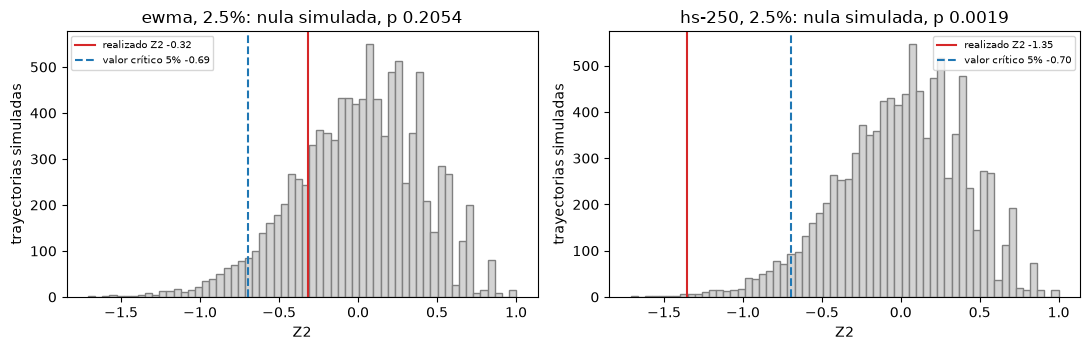

In [4]:
# La nula coherente con la cola del proceso entregada a la prueba de Acerbi-Szekely del motor, para cuatro
# modelos en ambos niveles
from pipeline.cases.c11.documents import tail_null
from riskvalidation.validation.market import acerbi_szekely

nulls = {}
print(f"{'model':11s} {'alpha':>6s} {'Z2':>9s} {'p':>9s} {'crit 5%':>9s}")
for mid in ("hs-250", "ewma", "garch-t", "dn-rolling"):
    for level in models[mid]["by_level"]:
        alpha = level["alpha"]
        var, es = np.array(level["var"]), np.array(level["es"])
        draws = []
        simulate = tail_null(var, es, alpha, draws)
        result = acerbi_szekely(loss, var, es, alpha, simulate, model_id=mid, statistic="Z2", n_sim=10000, seed=42)
        nulls[(mid, alpha)] = (np.array(draws), result)
        critical = result.extras["critical_5pct"]
        print(f"{mid:11s} {alpha:6.3f} {result.statistic:9.4f} {result.p_value:9.6f} {critical:9.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, mid in zip(axes, ("ewma", "hs-250")):
    draws, result = nulls[(mid, 0.025)]
    ax.hist(draws, bins=60, color="lightgrey", edgecolor="grey")
    ax.axvline(result.statistic, color="tab:red", label=f"realizado Z2 {result.statistic:.2f}")
    critical = result.extras["critical_5pct"]
    ax.axvline(critical, color="tab:blue", linestyle="--", label=f"valor crítico 5% {critical:.2f}")
    ax.set_title(f"{mid}, 2.5%: nula simulada, p {result.p_value:.4f}")
    ax.set_xlabel("Z2")
    ax.set_ylabel("trayectorias simuladas")
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Cada histograma es la nula simulada de $Z_2$ del propio motor al 2,5 por ciento, 10.000 trayectorias sorteadas desde el VaR y la ES del modelo, centrada cerca de cero como exige la construcción. El $Z_2$ realizado de `ewma` (-0,3160) cae dentro del grueso de su nula y su valor p es 0,205379, mientras que el de `hs-250` (-1,3513) cae muy adentro de la cola izquierda, bajo el valor crítico de 5 por ciento de -0,6950, con un valor p de 0,001900. La tabla muestra la misma división al 1 por ciento: `ewma` y `garch-t` no se rechazan (p 0,255774 y 0,308069) y `hs-250` y `dn-rolling` sí, este último en el piso de 0,000100, el menor valor p que pueden dar 10.000 sorteos. La figura muestra dónde cae un valor realizado en una nula construida sobre un supuesto declarado de la cola; no prueba ese supuesto.

### Paso 3: el valor crítico pertenece al modelo, y los umbrales publicados son un punto de referencia

La sugerencia publicada para $Z_2$ es una zona amarilla bajo $-0,70$ y una zona roja bajo $-1,8$, para $T = 250$ días con $\alpha = 2,5$ por ciento (Acerbi y Szekely; verificada aquí solo mediante la fuente secundaria de Moldenhauer y Pitera, 2017, sección 6). El motor las guarda en `extras["reference"]` y dice que son un punto de referencia publicado, no un umbral. Los valores simulados muestran por qué: los valores críticos al 5 por ciento y al 0,01 por ciento dependen de la trayectoria de VaR y ES del modelo, porque el exceso simulado escala con $\mathrm{ES}_t - \mathrm{VaR}_t$ y el estadístico divide por $\mathrm{ES}_t$. La celda lista, para los modelos con ES en `fx-2008`, el rango de los valores críticos que simula el motor en cada nivel y dibuja el $Z_2$ realizado de cada modelo frente a su valor crítico de 5 por ciento y la referencia. La luz compara el valor p con 5 por ciento (ámbar) y 0,01 por ciento (rojo), los valores por defecto del motor.

alfa 0.01: valor crítico 5% de -1.211 a -1.056 | 0,01% de -3.587 a -2.854
alfa 0.025: valor crítico 5% de -0.723 a -0.687 | 0,01% de -1.762 a -1.559
referencia publicada (T = 250, alfa = 0,025): {'yellow': -0.7, 'red': -1.8}


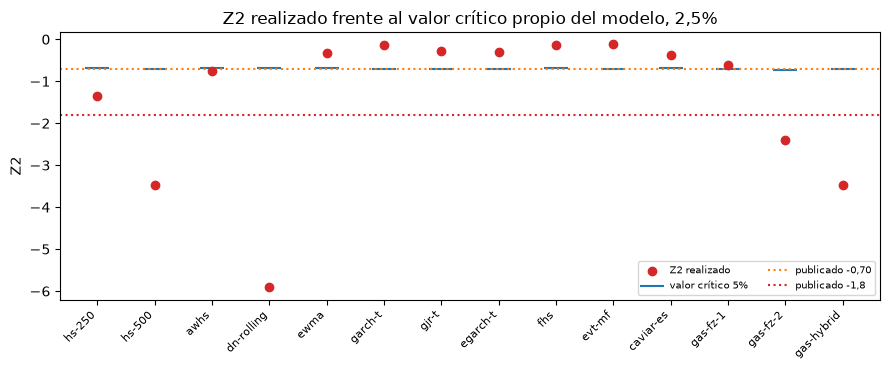

In [5]:
# Valores críticos simulados de Z2 de los 14 modelos con ES en ambos niveles, frente al punto de referencia
# publicado
reference = {"yellow": -0.70, "red": -1.8}
table = {}
for alpha in (0.01, 0.025):
    rows = []
    for mid in with_es:
        level = [lv for lv in models[mid]["by_level"] if lv["alpha"] == alpha][0]
        var, es = np.array(level["var"]), np.array(level["es"])
        simulate = tail_null(var, es, alpha, [])
        result = acerbi_szekely(loss, var, es, alpha, simulate, model_id=mid, statistic="Z2", n_sim=10000, seed=42)
        extras = result.extras
        rows.append((result.statistic, extras["critical_5pct"], extras["critical_0_01pct"], result.p_value))
    table[alpha] = np.array(rows)
    print(f"alfa {alpha}: valor crítico 5% de {table[alpha][:, 1].min():.3f} a {table[alpha][:, 1].max():.3f}"
          f" | 0,01% de {table[alpha][:, 2].min():.3f} a {table[alpha][:, 2].max():.3f}")
print(f"referencia publicada (T = 250, alfa = 0,025): {reference}")

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(with_es))
ax.scatter(x, table[0.025][:, 0], color="tab:red", zorder=3, label="Z2 realizado")
ax.scatter(x, table[0.025][:, 1], marker="_", s=300, color="tab:blue", label="valor crítico 5%")
ax.axhline(reference["yellow"], color="tab:orange", linestyle=":", label="publicado -0,70")
ax.axhline(reference["red"], color="tab:red", linestyle=":", label="publicado -1,8")
ax.set_xticks(x, with_es, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Z2")
ax.set_title("Z2 realizado frente al valor crítico propio del modelo, 2,5%")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

Las marcas azules son los valores críticos de 5 por ciento de los 14 modelos al 2,5 por ciento y quedan casi sobre el $-0,70$ publicado, entre -0,723 y -0,687, de modo que para este nivel y tamaño de muestra la referencia es un buen resumen. Al 1 por ciento los valores críticos van de -1,211 a -1,056, lejos de la referencia, y los valores de 0,01 por ciento van de -3,587 a -2,854 al 1 por ciento y de -1,762 a -1,559 al 2,5 por ciento, menos negativos que el $-1,8$ publicado. Los puntos rojos muestran el veredicto: cinco modelos, `hs-250`, `hs-500`, `dn-rolling`, `gas-fz-2` y `gas-hybrid`, caen muy por debajo de su valor crítico y los demás quedan sobre él. La figura muestra que el par publicado es una referencia para un nivel y un tamaño de muestra, y que los valores críticos del motor dependen de la trayectoria de VaR y ES del propio modelo.

### Paso 4: Du-Escanciano, una prueba construida sobre toda la cola

$Z_2$ mira solo los días de excepción. Du y Escanciano (2017) usan la **transformada integral de probabilidad** (PIT) $u_t = F_t(y_t)$, la posición del retorno realizado en la distribución predictiva del modelo, que es uniforme si la distribución es correcta. El proceso de violación acumulada $H_t(\alpha) = \frac{1}{\alpha}(\alpha - u_t)\,\mathbb 1\{u_t \le \alpha\}$ mide cuán adentro de la cola de nivel $\alpha$ cayó la observación: es 0 fuera de la cola y crece hasta 1 en el extremo. Bajo pronósticos correctos $E[H_t] = \alpha/2$ y $\mathrm{Var}(H_t) = \alpha(1/3 - \alpha/4)$, lo que da

$$U_{ES} = \frac{\sqrt{T}\,(\bar H - \alpha/2)}{\sqrt{\alpha(1/3-\alpha/4)}} \xrightarrow{d} N(0,1), \qquad C_{ES}(m) = T\sum_{j=1}^{m}\hat\rho_j^{\,2} \xrightarrow{d} \chi^2_m$$

donde $\hat\rho_j$ son las autocorrelaciones de $H_t - \alpha/2$: el primer estadístico contrasta el nivel de la cola, el segundo si las violaciones de la cola vienen en secuencias. Ambos necesitan una distribución predictiva, así que el notebook usa dos modelos cuya distribución es una normal que los pronósticos versionados determinan. `ewma` tiene media cero y una volatilidad que fija el VaR versionado (paso 4 del notebook 02). Para `dn-rolling` la media $\mu$ y la volatilidad $\sigma$ son las dos incógnitas de las dos fórmulas delta-normales $v = \mu + z\sigma$ y $e = \mu - \sigma\varphi(z)/\alpha$, que la celda invierte día a día. Las pruebas asintóticas simples ignoran la incertidumbre de los parámetros estimados, como dicen las notas del motor. La batería C11 versionada no corre estas pruebas, así que no hay filas versionadas con qué comparar.

ewma       alfa 0.010 | U_ES   1.131 p 0.1291 verde
           C_ES(5) p 0.0267 rojo
ewma       alfa 0.025 | U_ES   0.434 p 0.3323 verde
           C_ES(5) p 0.0062 rojo
dn-rolling alfa 0.010 | U_ES  18.909 p 0.0000 rojo
           C_ES(5) p 0.1283 verde
dn-rolling alfa 0.025 | U_ES  14.780 p 0.0000 rojo
           C_ES(5) p 0.0634 ámbar


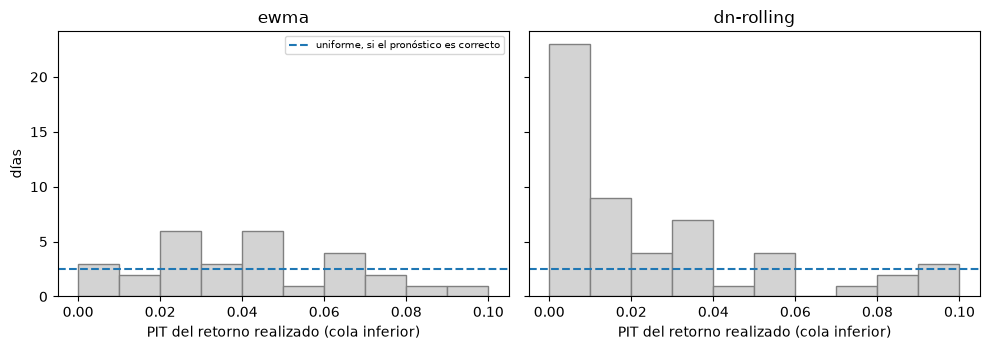

In [6]:
# La normal predictiva de ewma y dn-rolling desde el VaR y la ES versionados, los PIT y las pruebas de Du-
# Escanciano
from riskvalidation.validation.market import du_escanciano_conditional, du_escanciano_unconditional

returns = -loss
pits = {}
for mid in ("ewma", "dn-rolling"):
    for level in models[mid]["by_level"]:
        alpha = level["alpha"]
        var, es = np.array(level["var"]), np.array(level["es"])
        z = stats.norm.ppf(alpha)
        sigma = var / -z if mid == "ewma" else (es - var) / (stats.norm.pdf(z) / alpha + z)
        mu = np.zeros_like(sigma) if mid == "ewma" else -var - z * sigma
        pit = stats.norm.cdf((returns - mu) / sigma)
        pits[(mid, alpha)] = (pit, sigma)
        unconditional = du_escanciano_unconditional(pit, alpha, model_id=mid)
        conditional = du_escanciano_conditional(pit, alpha, lags=5, model_id=mid)
        print(f"{mid:10s} alfa {alpha:5.3f} | U_ES {unconditional.statistic:7.3f} p {unconditional.p_value:.4f} "
              f"{LIGHT[unconditional.light.value]}")
        print(f"{'':10s} C_ES(5) p {conditional.p_value:.4f} {LIGHT[conditional.light.value]}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, mid in zip(axes, ("ewma", "dn-rolling")):
    ax.hist(pits[(mid, 0.01)][0], bins=np.linspace(0, 0.1, 11), color="lightgrey", edgecolor="grey")
    ax.axhline(0.01 * loss.size, color="tab:blue", linestyle="--", label="uniforme, si el pronóstico es correcto")
    ax.set_xlabel("PIT del retorno realizado (cola inferior)")
    ax.set_title(mid)
axes[0].set_ylabel("días")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

Cada histograma muestra dónde cayeron los retornos realizados en el 10 por ciento inferior de la distribución predictiva del propio modelo; bajo un pronóstico correcto las barras serían planas en la línea de trazos, 2,51 días por tramo. Para `dn-rolling` 23 días caen en el primer tramo, las 23 excepciones del nivel de 1 por ciento, y el estadístico incondicional es 18,909 (p 0,0000, rojo): el nivel de la cola está errado. Para `ewma` el primer tramo tiene 3 días, cerca de la línea de trazos, y $U_{ES}$ no rechaza (1,131, p 0,1291), pero la prueba condicional sí (p 0,0267 al 1 por ciento y 0,0062 al 2,5 por ciento): los días que caen hondo en la cola vienen en secuencias, algo que $Z_2$, construido solo sobre los días de excepción, no puede ver. La figura muestra toda la cola y no solo los días de excepción; no muestra el orden en el tiempo, que solo lee el estadístico condicional.

### Paso 5: McNeil-Frey, el tamaño del exceso sobre la ES

McNeil y Frey (2000) miran los días de excepción y preguntan si el exceso sobre la ES, escalado por la volatilidad del día, es cero en promedio: $r_t = (L_t - \mathrm{ES}_t)/\sigma_t$ debería ser independiente con media cero cuando la ES es correcta, y una media positiva significa que la ES es demasiado baja. La función `mcneil_frey_residual_test` del motor recibe las pérdidas, el VaR, la ES y $\sigma_t$, y contrasta una media cero con un remuestreo unilateral: los residuos centrados en su media se remuestrean y $p = (1 + \#\{\bar r^* \ge \bar r\})/(n_{boot}+1)$. Es una prueba del **tamaño** de las pérdidas más allá del VaR que requiere pocos supuestos, y necesita al menos dos excepciones. La ejecutamos con el $\sigma_t$ del paso 4.

ewma       alfa 0.010 | excepciones  3 | residuo medio  0.331 | p 0.0374 | rojo
ewma       alfa 0.025 | excepciones  8 | residuo medio  0.075 | p 0.3325 | verde
dn-rolling alfa 0.010 | excepciones 23 | residuo medio  0.648 | p 0.0002 | rojo
dn-rolling alfa 0.025 | excepciones 35 | residuo medio  0.557 | p 0.0001 | rojo


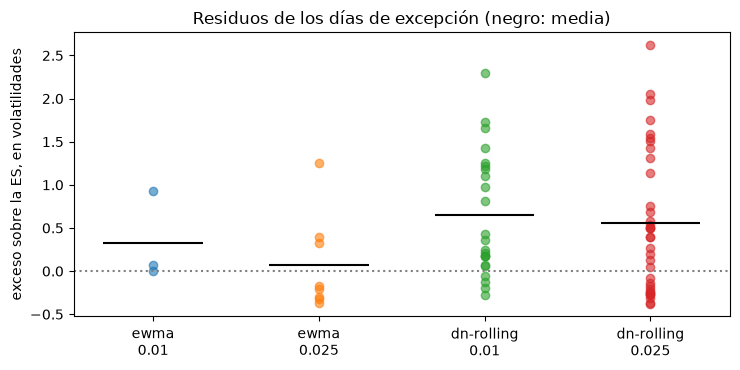

In [7]:
# La prueba de residuos de McNeil-Frey sobre los días de excepción de los mismos dos modelos, con la sigma
# del paso anterior
from riskvalidation.validation.market import mcneil_frey_residual_test

residuals = {}
for mid in ("ewma", "dn-rolling"):
    for level in models[mid]["by_level"]:
        alpha = level["alpha"]
        var, es = np.array(level["var"]), np.array(level["es"])
        sigma = pits[(mid, alpha)][1]
        result = mcneil_frey_residual_test(loss, var, es, sigma, alpha, model_id=mid, n_boot=10000, seed=0)
        exceed = loss > var
        residuals[(mid, alpha)] = (loss[exceed] - es[exceed]) / sigma[exceed]
        print(f"{mid:10s} alfa {alpha:5.3f} | excepciones {result.n_events:2d} | "
              f"residuo medio {result.statistic:6.3f} | p {result.p_value:.4f} | {LIGHT[result.light.value]}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for position, values in enumerate(residuals.values()):
    ax.scatter(np.full(values.size, position), values, alpha=0.6)
    ax.hlines(values.mean(), position - 0.3, position + 0.3, color="black")
ax.axhline(0, color="grey", linestyle=":")
ax.set_xticks(range(len(residuals)), [f"{m}\n{a}" for m, a in residuals])
ax.set_ylabel("exceso sobre la ES, en volatilidades")
ax.set_title("Residuos de los días de excepción (negro: media)")
fig.tight_layout()
plt.show()

Cada punto es el exceso de un día de excepción sobre la ES pronosticada, en unidades de la volatilidad de ese día, y la barra negra es la media; una ES correcta pondría la media en cero. Para `dn-rolling` la media es 0,648 sobre 23 excepciones al 1 por ciento (p de remuestreo 0,0002) y 0,557 sobre 35 al 2,5 por ciento: las pérdidas más allá del VaR están cerca de media volatilidad diaria sobre la ES que pronosticó, y casi todos los puntos están sobre cero. Para `ewma` al 1 por ciento la media de 0,331 es roja (p 0,0374) pero se apoya en solo 3 residuos, mientras que al 2,5 por ciento la media es 0,075 sobre 8 y la prueba es verde (p 0,3325). La figura muestra el tamaño del exceso que $Z_2$ pliega en un solo número; con tan pocas excepciones una luz roja sobre tres residuos es un indicio, no un veredicto.

### Paso 6: las mismas pruebas en una segunda ventana

Un resultado en una ventana es una anécdota. La celda corre las pruebas de Acerbi-Szekely, Du-Escanciano y McNeil-Frey para `ewma` en `rates-2022`, donde el mismo modelo está disponible de la misma manera. Lo que importa es el contraste entre pruebas: sobre un mismo pronóstico pueden discrepar, y el validador las lee juntas.

In [8]:
# ewma en rates-2022: las pruebas de Acerbi-Szekely, Du-Escanciano y McNeil-Frey sobre el mismo pronóstico
rates = docs["rates-2022"]["outputs"]
rates_loss = np.array(rates["grid"]["realised_loss"]["loss"])
ewma_rates = {m["model_id"]: m for m in rates["models"]}["ewma"]
for level in ewma_rates["by_level"]:
    alpha = level["alpha"]
    var, es = np.array(level["var"]), np.array(level["es"])
    sigma = var / -stats.norm.ppf(alpha)
    pit = stats.norm.cdf(-rates_loss / sigma)
    simulate = tail_null(var, es, alpha, [])
    z2 = acerbi_szekely(rates_loss, var, es, alpha, simulate, model_id="ewma", statistic="Z2", n_sim=10000, seed=42)
    unconditional = du_escanciano_unconditional(pit, alpha, model_id="ewma")
    conditional = du_escanciano_conditional(pit, alpha, lags=5, model_id="ewma")
    residual = mcneil_frey_residual_test(rates_loss, var, es, sigma, alpha, model_id="ewma", n_boot=10000, seed=0)
    print(f"alfa {alpha:5.3f} | excepciones {int((rates_loss > var).sum())} | "
          f"Z2 {z2.statistic:.4f} p {z2.p_value:.4f}")
    print(f"  U_ES p {unconditional.p_value:.4f} | C_ES p {conditional.p_value:.4f}")
    print(f"  McNeil-Frey p {residual.p_value:.4f}")

alfa 0.010 | excepciones 6 | Z2 -1.5073 p 0.0183
  U_ES p 0.0307 | C_ES p 0.7818
  McNeil-Frey p 0.2841
alfa 0.025 | excepciones 9 | Z2 -0.5913 p 0.0779
  U_ES p 0.0254 | C_ES p 0.4295
  McNeil-Frey p 0.0993


## Resultados

**Respuesta:** Qué prueba ve la falla depende de la falla. `dn-rolling` falla las tres: $Z_2$ de -10,4033 (p 0,0001), un estadístico incondicional de Du-Escanciano de 18,909 y un exceso medio de McNeil-Frey de 0,648 volatilidades sobre 23 excepciones (p 0,0002). `ewma` pasa la prueba de $Z_2$ en los dos niveles (p 0,255774 y 0,205379) pero la prueba condicional de Du-Escanciano lo rechaza en ambos (p 0,0267 y 0,0062): los días de cola profunda de su ES vienen en secuencias que $Z_2$ no puede ver.

- **Z1 y Z2 a mano.** 14 de los 17 modelos pronostican una ES; los otros tres (`cf-rolling`, `caviar-sav`, `caviar-as`) no se pueden probar. `hs-250` al 1 por ciento tiene $Z_1 = -0,0691$ y $Z_2 = -3,2592$ con 10 excepciones; `dn-rolling` tiene $Z_1 = -0,2444$ y $Z_2 = -10,4033$ con 23.
- **La nula.** Con la nula coherente con la cola del proceso, 10.000 sorteos y la semilla 42 el motor da a `hs-250` al 1 por ciento un valor p de 0,000200 y un valor crítico de 5 por ciento de -1,0906, y a `ewma` 0,255774 y -1,1035. El menor valor p que puede dar una corrida es 0,0001, que es lo que muestran las filas rojas de `dn-rolling`.
- **Un valor crítico por modelo.** Al 2,5 por ciento el valor crítico de 5 por ciento va de -0,723 a -0,687 en los 14 modelos y el -0,70 publicado cae dentro de ese rango; el valor de 0,01 por ciento va de -1,762 a -1,559, menos negativo que el -1,8 publicado. Al 1 por ciento los valores están lejos de la referencia: -1,211 a -1,056 al 5 por ciento y -3,587 a -2,854 al 0,01 por ciento.
- **Du-Escanciano.** Para `ewma` la prueba incondicional no rechaza (p 0,1291 al 1 por ciento y 0,3323 al 2,5 por ciento) pero la condicional sí (p 0,0267 y 0,0062). Para `dn-rolling` el nivel está errado: $U_{ES}$ es 18,909 al 1 por ciento y 14,780 al 2,5 por ciento.
- **McNeil-Frey.** `dn-rolling` tiene un exceso estandarizado medio de 0,648 sobre 23 excepciones al 1 por ciento y 0,557 sobre 35 al 2,5 por ciento; `ewma` al 1 por ciento es rojo (0,331, p 0,0374) con solo 3 excepciones.
- **Una segunda ventana.** Para `ewma` en `rates-2022`, $Z_2$ es -1,5073 y -0,5913 (p 0,0183 y 0,0779), pero la prueba incondicional de Du-Escanciano es roja en ambos niveles (p 0,0307 y 0,0254). Las pruebas no son redundantes.

Lo que este notebook no muestra: cómo elegir entre modelos que pasan todas ellas (notebook 05).

## Resumen

- Una prueba retrospectiva de VaR cuenta excepciones; una de ES debe mirar el tamaño de las pérdidas más allá del VaR. $Z_1$ lo hace sobre los días de excepción, $Z_2$ penaliza además un número equivocado de ellos, y ambos son cero bajo pronósticos correctos y negativos cuando se subestima el riesgo.
- Un valor crítico necesita una nula. El motor la pide al usuario; Contraste suministra una nula coherente con la cola para todos los escalones (un exceso exponencial de media $\mathrm{ES} - \mathrm{VaR}$), de modo que los valores críticos de cada modelo salen de su propia trayectoria de VaR y ES, bajo un supuesto declarado sobre la forma de la cola.
- Los $-0,70$ y $-1,8$ publicados son un punto de referencia para $T = 250$ y $\alpha = 2{,}5$ por ciento, verificado solo por una fuente secundaria; los valores críticos simulados difieren por modelo y nivel.
- Du-Escanciano usa toda la distribución predictiva mediante el PIT, McNeil-Frey el tamaño del exceso sobre la ES; necesitan una distribución predictiva o una volatilidad, y sobre un mismo pronóstico pueden discrepar de $Z_2$.
- Ninguna de estas pruebas reemplaza a las pruebas de conteo del notebook 03; las compuertas de elegibilidad de la escalera usan Kupiec, cobertura condicional y $Z_2$ juntos.

**Qué probar después.** Cambia `n_sim` en el paso 2 a 1000 y mira el valor p y el valor crítico de 0,01 por ciento, que necesita al menos 10.000 sorteos para resolverse; luego lee el notebook 05, que ordena los modelos que pasan.

## Referencias

- Acerbi, C. y Szekely, B. (2014), Backtesting expected shortfall, Risk, diciembre de 2014 (texto primario no recuperado). El punto de referencia de -0,70 y -1,8 se lee a través de Moldenhauer, G. y Pitera, M. (2017), Backtesting expected shortfall, sección 6. https://arxiv.org/abs/1709.01337
- Du, Z. y Escanciano, J. C. (2017), Backtesting expected shortfall: accounting for tail risk, Management Science 63(4). https://doi.org/10.1287/mnsc.2015.2342
- McNeil, A. J. y Frey, R. (2000), Estimation of tail-related risk measures for heteroscedastic financial time series: an extreme value approach, Journal of Empirical Finance 7(3-4). https://doi.org/10.1016/S0927-5398(00)00012-8
- Nolde, N. y Ziegel, J. F. (2017), Elicitability and backtesting: perspectives for banking regulation, Annals of Applied Statistics 11(4). https://doi.org/10.1214/17-AOAS1041